# <font color=#4466ff>**Node-Specific Module Weighting for Multi-Label Node Classification with GNN-MultiFix** 
</font>

By: Alexander van den Arend Schmidt, Adela Greganova, Tim Haasdijk, Huib Sprangers and Lotte Veerbeek

##### <font color=#4466ff>**Research Question**: </font>_To what extent does node-specific weighting of the feature, label and positional representations improve GNN-MultiFix on multi-label node classification, and how do the learned weights relate to homophily?_

To answer this, we test three main hypotheses:
* **H1**: on datasets where a simple baseline outperforms GNN-MultiFix, weighting improves each of AP, macro-F1 and AUROC by at least 10% relative to GNN-MultiFix. 
* **H2**: on synthetic graphs, the mean label-module weight increases with graph homophily. 
* **H3**: within a graph, a node’s label-module weight correlates positively with its local label homophily.

<font color=#9944ff>**Contents**
</font>

0. Setup
1. Data
2. Model: GNN-MultiFix with node-specific module weighting
3. Training and evaluation (with a small demo run)
4. Results: does weighting improve GNN-MultiFix? (**H1**)
5. Ablation: weighting or normalisation?
6. What do the weights learn? (**H2**, **H3**)
7. Interpretability: are the weights faithful?
8. Scalability
9. Training curves
10. Conclusion

<font color=#9944ff>**How to use this notebook.** </font> Run it from the root of the repository (it imports `data_loader.py`, `model.py` and `evaluation.py`). We ran all experiments with `run_report_experiments.sh`, which calls `train.py` once per dataset, split and variant (189 runs for the results below), and writes them to `results_v2/`. Sections 1–3 explain and demonstrate the pipeline: Section 3 trains two models on PCG, which takes under a minute on a laptop CPU. Sections 4–9 rebuild every table and figure in the report from the saved runs, so they need no training.

<font color="Red">**NOTE:** </font>Unzip split_features.zip under `data/dblp/split_features.zip` before running.

### <font color=#4466ff>**0: Setup**

</font> Requirements: Python 3.11 with `torch`, `torch_geometric`, `torch_sparse`, `gensim`, `scikit-learn`, `scipy`, `pandas` and `matplotlib` (we used the `graphML` conda environment). Get the datasets by cloning https://github.com/Tianqi-py/MLGNC.git into `data/`. Create the DeepWalk embeddings of the synthetic graphs with `generate_deepwalk_embeddings.py` (see `README.md`).

In [65]:
## Imports
import contextlib
import copy
import glob
import io
import os
import random
import time
import warnings
from matplotlib.lines import Line2D

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from gensim.models import KeyedVectors
from scipy.stats import spearmanr
from torch_geometric.nn import GCNConv
from torch_sparse import SparseTensor

from data_loader import load_blogcatalog, load_DBLP, load_eukloc, load_humloc, load_hyper_data, load_pcg
from evaluation import evaluate, tune_per_label_thresholds
from model import FPLPGCN_dw  # GNN-MultiFix MLP-1, the unweighted base model

assert os.path.isfile("train.py"), "Run this notebook from the root of the repository"
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

RESULTS_DIR = "results_v2"  # where run_report_experiments.sh wrote the runs
RUN_DEMO = True             # Section 3: train MultiFix and the proposed variant on PCG, split 0 (~1 min on CPU)

# the seven graphs: key -> (data_name, homo_level, display name)
DATASETS = {
    "blogcatalog":   ("blogcatalog", None, "BlogCatalog"),
    "pcg":           ("pcg", None, "PCG"),
    "dblp":          ("dblp", None, "DBLP"),
    "hyper_homo025": ("hyper", "homo025", "Syn-0.25"),
    "hyper_homo045": ("hyper", "homo045", "Syn-0.45"),
    "hyper_homo065": ("hyper", "homo065", "Syn-0.65"),
    "hyper_homo085": ("hyper", "homo085", "Syn-0.85"),
}
NAMES = {k: v[2] for k, v in DATASETS.items()}
SYNTHETIC = ["hyper_homo025", "hyper_homo045", "hyper_homo065", "hyper_homo085"]
SYN_HOMOPHILY = {"hyper_homo025": 0.25, "hyper_homo045": 0.45, "hyper_homo065": 0.65, "hyper_homo085": 0.85}
SPLITS = [0, 1, 2]
MODULES = ["feature", "label", "positional"]

# plot colours (the same as in the report figures)
MODULE_COLORS = {"feature": "#2a78d6", "label": "#eb6834", "positional": "#1baf7a"}
VARIANT_COLORS = {"MultiFix MLP-1": "#898781", "Learned weights": "#2a78d6", "Weights x3": "#eb6834",
                  "Normalised (proposed)": "#1baf7a"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True})

### <font color=#4466ff>**1: Load dataset**

</font>
We use three real-world and four synthetic multi-label graphs:

| Dataset | Nodes | Labels | Node features | Label homophily |
|---|---|---|---|---|
| BlogCatalog | 10,312 | 39 | none (one-hot node ids) | 0.10 |
| PCG | 3,233 | 15 | 32 | 0.17 |
| DBLP | 28,702 | 4 | 300 | 0.76 |
| Syn-0.25 … Syn-0.85 (hyperspheres) | 3,000 | 20 | 10 | 0.25 / 0.45 / 0.65 / 0.85 |

Every dataset has three splits (`split_0.pt`, `split_1.pt` and `split_2.pt`, 60/20/20). The label module needs the labels as input. The loaders therefore provide `G.y_pad`, a copy of `G.y` in which every validation and test node gets the uniform vector $\frac1C\mathbf 1$, so the model never sees their labels. Each loader also attaches the 64-dimensional DeepWalk embedding of the graph as `G.deep_walk_emb`, which is the input of the positional module.

Two corrections to the data:
* The synthetic graphs share one feature/label file but have different edges. `load_hyper_data` attaches the same DeepWalk embedding to every homophily level, so we replace it with the embedding of the graph at that level (`<homo_level>.emb`).
* In DBLP the provided splits overlap. We remove from the validation set every node that is also in the training or test set (`clean_validation`).

In [27]:
data_name = "blogcatalog"  # "pcg", "blogcatalog", "dblp", "hyper", "humloc" or "eukloc"
homo_level = None          # for data_name="hyper": "homo025", "homo045", "homo065" or "homo085"
split_name = "split_0.pt"
train_percent = 0.6


def load_data(data_name, split_name="split_0.pt", train_percent=0.6, homo_level=None):
    data_name = data_name.lower()
    if data_name == 'pcg':
        return load_pcg(split_name=split_name, train_percent=train_percent)
    if data_name == 'blogcatalog':
        return load_blogcatalog(split_name=split_name, train_percent=train_percent)
    if data_name == 'dblp':
        return load_DBLP(split_name=split_name, train_percent=train_percent)
    if data_name == 'hyper':
        G = load_hyper_data(split_name=split_name, train_percent=train_percent, homo_level=homo_level)
        # load_hyper_data uses one hypersphere.emb for every homophily level, but each level is a different graph,
        # so the positional module gets the DeepWalk embedding of this level's graph (<homo_level>.emb)
        emb_path = os.path.join("data", "Hyperspheres_10_10_0", homo_level + ".emb")
        if not os.path.isfile(emb_path):
            raise FileNotFoundError(
                f"Missing {emb_path}. Generate it with: python generate_deepwalk_embeddings.py "
                f"--edges data/Hyperspheres_10_10_0/{homo_level}.txt --output {emb_path} --num-nodes {G.num_nodes}")
        emb = KeyedVectors.load_word2vec_format(emb_path, binary=False)
        G.deep_walk_emb = torch.from_numpy(np.asarray([emb[str(n)] for n in range(G.num_nodes)])).float()
        return G
    if data_name == 'humloc':
        return load_humloc()
    if data_name == 'eukloc':
        return load_eukloc()
    raise ValueError(f"Unknown dataset {data_name}")


def clean_validation(G):
    """DBLP: drop validation nodes that are also training or test nodes, and give the training nodes back
    their labels in the label input (the loader padded them because they were in the validation set)."""
    overlap = G.val_mask & (G.train_mask | G.test_mask)
    print(f"clean_val: removing {overlap.sum().item()} overlapping nodes from the validation set")
    G.val_mask = G.val_mask & ~overlap
    G.y_pad[G.train_mask & ~G.test_mask] = G.y[G.train_mask & ~G.test_mask]
    return G


G = load_data(data_name, split_name, train_percent, homo_level)
print(G)

Loading dataset blogcatalog.mat...
Data(x=[10312, 10312], edge_index=[2, 667966], y=[10312, 39], train_mask=[10312], val_mask=[10312], test_mask=[10312], num_nodes=10312, n_id=[10312], y_pad=[10312, 39], LabelCor=[39, 39], deep_walk_emb=[10312, 64])


In [28]:
def quiet(f, *args, **kwargs):
    """Call f without printing (the data loaders are verbose)."""
    with contextlib.redirect_stdout(io.StringIO()):
        return f(*args, **kwargs)


def get_graph(key, split=0, seed=0):
    """Load dataset `key` (a key of DATASETS) with split `split`, as in train.py (seeded, DBLP cleaned)."""
    data_name, homo_level, _ = DATASETS[key]
    set_seed(seed)  # seed before loading: some loaders draw random embeddings for isolated nodes
    G = quiet(load_data, data_name, f"split_{split}.pt", 0.6, homo_level)
    if data_name == "dblp":
        G = quiet(clean_validation, G)
    return G


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def label_homophily(G):
    """Mean Jaccard overlap of the label sets of the two end nodes of every edge."""
    y = G.y.float()
    src, dst = G.edge_index
    inter = (y[src] * y[dst]).sum(1)
    union = ((y[src] + y[dst]) > 0).float().sum(1).clamp(min=1)
    return (inter / union).mean().item()


rows = []
for key in DATASETS:
    G = get_graph(key)
    rows.append({"dataset": NAMES[key], "nodes": G.num_nodes, "edges (undirected)": G.edge_index.shape[1] // 2,
                 "feature dim": G.x.shape[1], "labels": G.y.shape[1],
                 "labels per node": round(G.y.sum(1).float().mean().item(), 2),
                 "label homophily": round(label_homophily(G), 3),
                 "train / val / test": f"{G.train_mask.sum().item()} / {G.val_mask.sum().item()} / "
                                       f"{G.test_mask.sum().item()}"})
    del G
pd.DataFrame(rows).set_index("dataset")

,nodes,edges (undirected),feature dim,labels,labels per node,label homophily,train / val / test
dataset,,,,,,,
BlogCatalog,10312,333983,10312,39,1.40,0.103,6187 / 2062 / 2063
PCG,3233,37351,32,15,1.93,0.174,1939 / 647 / 647
DBLP,28702,68335,300,4,1.18,0.761,17221 / 1138 / 5741
Syn-0.25,3000,161078,10,20,3.23,0.249,1800 / 600 / 600
Syn-0.45,3000,25439,10,20,3.23,0.453,1800 / 600 / 600
Syn-0.65,3000,11566,10,20,3.23,0.655,1800 / 600 / 600
Syn-0.85,3000,6852,10,20,3.23,0.857,1800 / 600 / 600


Note the confound in the synthetic graphs: higher homophily comes with far fewer edges (161K edges at 0.25 against 7K at 0.85). This matters for H2.

### <font color=#4466ff>**2: Model definition**

</font>

**Base model: GNN-MultiFix MLP-1** (`FPLPGCN_dw` in `model.py`). For each node $i$ it computes three representations:
* the **feature module**: two GCN layers on the features $\mathbf X$, giving $\mathbf h_i^{F}\in\mathbb R^{256}$;
* the **label module**: five GCN layers on the padded labels `y_pad`, giving $\mathbf h_i^{L}\in\mathbb R^{C}$;
* the **positional module**: the precomputed 64-dimensional DeepWalk embedding $\mathbf h_i^{P}$.

One linear layer maps the concatenation $[\mathbf h_i^{F};\mathbf h_i^{L};\mathbf h_i^{P}]$ to $C$ logits. A sigmoid turns them into label probabilities.

**Node-specific module weighting** (`FPLPGCN_dw_weighted`, defined below). A gate computes a weight $\alpha_i^m$ for every node $i$ and module $m\in\{F,L,P\}$. Following the node-level attention of AM-GCN, each module output is projected to a shared $d_g=16$-dimensional space, $\mathbf z_i^m=\mathbf P_m\mathbf h_i^m$. A shared network scores each projection, and a softmax over the three modules turns the scores into weights:

$$e_i^m=\mathbf q^\top\tanh(\mathbf W_a\mathbf z_i^m+\mathbf b_a),\qquad \alpha_i^m=\frac{\exp(e_i^m)}{\sum_k\exp(e_i^k)}.$$

We compare three ways to apply the weights before the classifier:

| Variant | Classifier input | Flags |
|---|---|---|
| Learned weights | $[\alpha_i^F\mathbf h_i^F;\ \alpha_i^L\mathbf h_i^L;\ \alpha_i^P\mathbf h_i^P]$ | `gate_norm=False, weight_scale=1` |
| Weights ×3 | $[3\alpha_i^F\mathbf h_i^F;\ 3\alpha_i^L\mathbf h_i^L;\ 3\alpha_i^P\mathbf h_i^P]$ | `gate_norm=False, weight_scale=3` |
| **Normalised (proposed)** | $\sum_m\alpha_i^m\,\mathrm{LN}(\mathbf F_m\mathbf h_i^m+\mathbf b_m)$ | `gate_norm=True` |

The weights sum to one, so in the first variant every module is on average scaled down by a factor of three compared with MultiFix. Multiplying by 3 restores the original scale. In both concatenation variants, however, the classifier can make up for a small weight by learning larger parameters for that module. A small weight then does not mean that the module is unimportant. The normalised variant prevents this. It maps every module to the same dimension and layer-normalises it without learnable parameters, so all modules have the same magnitude, and it sums the modules instead of concatenating them. The weights then control how much each module contributes, so they can be read as module importance.

The class also supports the ablations of Section 5: `gate_mode="uniform"` gives equal weights of 1/3, `gate_mode="global"` learns one weight vector shared by all nodes, and `module_mask` switches modules off. The fidelity test of Section 7 uses `module_mask` to remove a module at test time.

In [29]:
class FPLPGCN_dw_weighted(nn.Module):
    """GNN-MultiFix with learned per-node weighting of the feature, label and positional modules.

    Each module representation h^m is projected to a common space z^m = P_m h^m, scored with a
    shared scorer s^m = q^T tanh(W_a z^m + b_a), and the scores are turned into weights
    w = softmax(s^f, s^l, s^p). The classifier then sees [w^f h^f; w^l h^l; w^p h^p].

    With gate_norm=True each module is instead mapped to a shared space and normalised,
    u^m = LayerNorm(F_m h^m) without a learnable scale, and the classifier sees the weighted sum
    w^f u^f + w^l u^l + w^p u^p. The classifier can then no longer rescale one module to undo
    its weight, so the weights are the only per-module scale and can be read as module importance.

    With nonlinear=True a ReLU follows every GCN layer except the last one of each module, as in
    FPLPGCN_dw (MLP-1); otherwise the modules are linear, as in FPLPGCN_dw_linear.

    weight_scale multiplies the softmax weights before they are applied. With weight_scale=3, equal
    weights are 1 instead of 1/3, so the modules enter the output layer at the same scale as in plain
    MultiFix. module_weights always stores the softmax weights themselves (they sum to 1).
    """
    def __init__(self, input_dim, hidden_dim, output_dim, num_gcn_layers=2, num_label_layers=10, dw_dim=64,
                 gate_dim=16, gate_norm=False, nonlinear=False, weight_scale=1.0, multi_class=False,
                 gate_mode="learned", module_mask=(1, 1, 1)):
        """gate_mode: "learned" = per-node weights from the scorer (default), "uniform" = fixed 1/3 for every
        module, "global" = one learned weight vector shared by all nodes.
        module_mask: which of (feature, label, positional) are used; the weights of the used modules are
        renormalised to sum to 1. Training with e.g. (1, 0, 0) gives a single-module model, and changing
        the mask after training removes a module at test time (fidelity test)."""
        super(FPLPGCN_dw_weighted, self).__init__()
        self.nonlinear = nonlinear
        self.weight_scale = weight_scale
        assert gate_mode in ("learned", "uniform", "global")
        self.gate_mode = gate_mode
        self.register_buffer("module_mask", torch.tensor(module_mask, dtype=torch.float))
        if gate_mode == "global":
            self.global_logits = nn.Parameter(torch.zeros(3))

        # GCN layers for feature aggregation
        self.gcn_layers = nn.ModuleList()
        for _ in range(num_gcn_layers):
            self.gcn_layers.append(GCNConv(input_dim, hidden_dim))
            input_dim = hidden_dim

        # Linear layers for label aggregation
        self.label_layers = nn.ModuleList()
        for _ in range(num_label_layers):
            self.label_layers.append(GCNConv(output_dim, output_dim))

        # projections P_f, P_l, P_p to the common gate space
        self.proj_fp = nn.Linear(hidden_dim, gate_dim, bias=False)
        self.proj_lp = nn.Linear(output_dim, gate_dim, bias=False)
        self.proj_dw = nn.Linear(dw_dim, gate_dim, bias=False)

        # shared scorer: W_a, b_a and q
        self.score_hidden = nn.Linear(gate_dim, gate_dim)
        self.score_vector = nn.Linear(gate_dim, 1, bias=False)

        self.gate_norm = gate_norm
        if gate_norm:
            # F_f, F_l, F_p to the shared fusion space, normalised without a learnable scale
            self.fuse_fp = nn.Linear(hidden_dim, hidden_dim)
            self.fuse_lp = nn.Linear(output_dim, hidden_dim)
            self.fuse_dw = nn.Linear(dw_dim, hidden_dim)
            self.fuse_norm = nn.LayerNorm(hidden_dim, elementwise_affine=False)
            self.fusion_layer = nn.Linear(hidden_dim, output_dim)
        else:
            # Linear layer for fusion
            self.fusion_layer = nn.Linear(hidden_dim + output_dim + dw_dim, output_dim)
        self.smd = torch.nn.Sigmoid()

        self.multi_class = multi_class

        # (num_nodes, 3) weights for [feature, label, positional] from the last forward pass
        self.module_weights = None

    def score(self, z):
        return self.score_vector(torch.tanh(self.score_hidden(z)))

    def forward(self, x, y, edge_index, deep_walk_emb):

        #GCN layers for feature aggregation
        for i, gcn_layer in enumerate(self.gcn_layers):
            x = gcn_layer(x, edge_index)
            if self.nonlinear and i != len(self.gcn_layers) - 1:
                x = F.relu(x)

        x_label = y
        for j, label_layer in enumerate(self.label_layers):
            x_label = label_layer(x_label, edge_index)
            if self.nonlinear and j != len(self.label_layers) - 1:
                x_label = F.relu(x_label)

        # one score per module, softmax over the three modules for every node
        if self.gate_mode == "learned":
            scores = torch.cat((self.score(self.proj_fp(x)),
                                self.score(self.proj_lp(x_label)),
                                self.score(self.proj_dw(deep_walk_emb))), dim=1)
        elif self.gate_mode == "global":
            scores = self.global_logits.expand(x.shape[0], 3)
        else:  # uniform
            scores = torch.zeros(x.shape[0], 3, device=x.device)
        # drop the masked modules and renormalise the weights of the others
        scores = scores.masked_fill(self.module_mask == 0, float("-inf"))
        weights = F.softmax(scores, dim=1)
        self.module_weights = weights.detach()
        weights = self.weight_scale * weights

        if self.gate_norm:
            x_fused = (weights[:, 0:1] * self.fuse_norm(self.fuse_fp(x))
                       + weights[:, 1:2] * self.fuse_norm(self.fuse_lp(x_label))
                       + weights[:, 2:3] * self.fuse_norm(self.fuse_dw(deep_walk_emb)))
        else:
            x_fused = torch.cat((weights[:, 0:1] * x,
                                 weights[:, 1:2] * x_label,
                                 weights[:, 2:3] * deep_walk_emb), dim=1)
        self.all_emb = x_fused
        x_fused = self.fusion_layer(x_fused)

        if not self.multi_class:
            return self.smd(x_fused)
        else:
            return x_fused

In [30]:
# sanity check on PCG: the weights are a softmax per node, and the gate adds few parameters
G = get_graph("pcg")
common = dict(input_dim=G.x.shape[1], hidden_dim=256, output_dim=G.y.shape[1], num_gcn_layers=2,
              num_label_layers=5, dw_dim=G.deep_walk_emb.shape[1], multi_class=True)
base = FPLPGCN_dw(**common)
weighted = FPLPGCN_dw_weighted(gate_norm=True, nonlinear=True, **common)
with torch.no_grad():
    out = weighted(G.x, G.y_pad, G.edge_index, G.deep_walk_emb)
print("output shape:", tuple(out.shape), "| module weights shape:", tuple(weighted.module_weights.shape))
print("weights sum to 1 for every node:", torch.allclose(weighted.module_weights.sum(1), torch.ones(G.num_nodes)))
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"parameters: MultiFix MLP-1 {n_params(base):,}, normalised weighting {n_params(weighted):,}")

output shape: (3233, 15) | module weights shape: (3233, 3)
weights sum to 1 for every node: True
parameters: MultiFix MLP-1 85,295, normalised weighting 171,471


### <font color=#4466ff>**3: Training & Evaluation**

</font>

All variants share one training procedure, the same as in `train.py`:
* Adam with learning rate 0.01 and weight decay $5\cdot10^{-4}$, hidden size $d=256$, gate size $d_g=16$, 2 feature and 5 label propagation layers;
* full-batch training on the binary cross-entropy (on logits) over the training nodes, for at most 1000 epochs;
* early stopping on the validation BCE (patience 100); we evaluate the model from the epoch with the lowest validation loss;
* metrics on the test nodes: macro **Average Precision** (AP), macro **AUROC** and macro **F1**, where the F1 decision threshold of every label is tuned on the validation nodes (`evaluation.py`);
* for weighted models, a **fidelity test**: we remove one module at test time (its weight set to 0, the other two renormalised) and measure the drop in test AP.

We used one seed (0) per split and report mean ± std over the three splits.

In [31]:
# the variants of the report and their model settings
VARIANTS = {
    "MultiFix MLP-1":        dict(fusion="concat"),
    "Learned weights":       dict(fusion="weighted"),
    "Weights x3":            dict(fusion="weighted", gate_scale=3.0),
    "Normalised (proposed)": dict(fusion="weighted", gate_norm=True),
    # ablations (Section 5)
    "Equal weights (1/3)":   dict(fusion="weighted", gate_norm=True, gate_mode="uniform"),
    "One learned weight vector per dataset": dict(fusion="weighted", gate_norm=True, gate_mode="global"),
    "Feature module only":   dict(fusion="weighted", gate_norm=True, modules="F"),
    "Label module only":     dict(fusion="weighted", gate_norm=True, modules="L"),
    "Positional module only": dict(fusion="weighted", gate_norm=True, modules="P"),
}


def build_model(G, fusion="concat", gate_norm=False, gate_scale=1.0, gate_mode="learned", modules="FLP",
                hidden_dim=256, gate_dim=16, num_fp=2, num_lp=5):
    # multi_class=True skips the final sigmoid, so the models return logits (BCE is computed on logits)
    kwargs = dict(input_dim=G.x.shape[1], hidden_dim=hidden_dim, output_dim=G.y.shape[1], num_gcn_layers=num_fp,
                  num_label_layers=num_lp, dw_dim=G.deep_walk_emb.shape[1], multi_class=True)
    if fusion == "concat":
        return FPLPGCN_dw(**kwargs)
    return FPLPGCN_dw_weighted(gate_dim=gate_dim, gate_norm=gate_norm, nonlinear=True, weight_scale=gate_scale,
                               gate_mode=gate_mode, module_mask=tuple(int(m in modules) for m in "FLP"), **kwargs)


def train_and_evaluate(G, lr=0.01, weight_decay=5e-4, epochs=1000, patience=100, log_every=100, **variant):
    """Train one model on graph G and evaluate the epoch with the lowest validation loss (as in train.py)."""
    model = build_model(G, **variant)

    # a sparse adjacency matrix (and sparse features when they are mostly zeros) speeds up message passing
    graph = SparseTensor.from_edge_index(G.edge_index, sparse_sizes=(G.num_nodes, G.num_nodes)).t()
    x = G.x.to_sparse() if (G.x != 0).float().mean().item() < 0.05 else G.x
    forward = lambda: model(x, G.y_pad, graph, G.deep_walk_emb)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_epoch, best_state, bad_epochs, curve = float("inf"), -1, None, 0, []
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = F.binary_cross_entropy_with_logits(forward()[G.train_mask], G.y[G.train_mask])
        loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = F.binary_cross_entropy_with_logits(forward()[G.val_mask], G.y[G.val_mask]).item()
        curve.append((epoch, loss.item(), val_loss))
        if val_loss < best_val:
            best_val, best_epoch, best_state, bad_epochs = val_loss, epoch, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
        if log_every and epoch % log_every == 0:
            print(f"  epoch {epoch:4d}: train loss {loss.item():.4f}, val loss {val_loss:.4f}")
        if bad_epochs >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        probs = torch.sigmoid(forward()).numpy()
    y, val, test = G.y.numpy(), G.val_mask.numpy(), G.test_mask.numpy()
    thresholds = tune_per_label_thresholds(y[val], probs[val])  # per-label F1 thresholds tuned on validation
    out = {"best_epoch": best_epoch, "curve": curve, "model": model,
           "test": evaluate(y[test], probs[test], thresholds=thresholds)}

    if isinstance(model, FPLPGCN_dw_weighted):
        out["weights"] = model.module_weights.clone()
        if model.module_mask.sum() == 3:  # fidelity test: remove one module at test time
            for i, m in enumerate(MODULES):
                model.module_mask.fill_(1)
                model.module_mask[i] = 0
                with torch.no_grad():
                    p = torch.sigmoid(forward()).numpy()
                out[f"ap_without_{m}"] = evaluate(y[test], p[test], thresholds=thresholds)["ap_macro"]
            model.module_mask.fill_(1)
    return out

<font color=#9944ff>**Demo run.** </font>We train MultiFix MLP-1 and the proposed normalised variant on PCG (split 0, seed 0) and compare the result with the saved run from our experiments. The steps follow `train.py` in the same order (seed, load, build, train), so the numbers should match up to small floating-point differences between machines.

In [32]:
METRIC_COLS = {"ap_macro": "test AP", "macro_f1@per_label_threshold": "test macro-F1", "auroc_macro": "test AUROC"}

if RUN_DEMO:
    demo = {}
    rows = []
    for name, run_name in [("MultiFix MLP-1", "concat"), ("Normalised (proposed)", "weighted-norm")]:
        print(name)
        G = get_graph("pcg", split=0, seed=0)
        t0 = time.time()
        demo[name] = res = train_and_evaluate(G, **VARIANTS[name])
        saved = pd.read_csv(f"{RESULTS_DIR}/runs/pcg__relu__{run_name}__split_0__seed0.csv").iloc[0]
        for k, col in METRIC_COLS.items():
            rows.append({"variant": name, "metric": col, "this run": res["test"][k], "saved run": saved[f"test_{k}"]})
        print(f"  best epoch {res['best_epoch']}, {time.time() - t0:.0f} s")
        if "weights" in res:
            w = res["weights"][G.test_mask].mean(0)
            print("  mean module weights on test nodes (feature / label / positional): "
                  + " / ".join(f"{v:.2f}" for v in w))
    display(pd.DataFrame(rows).set_index(["variant", "metric"]).round(4))

MultiFix MLP-1
  epoch    0: train loss 0.6994, val loss 0.4320
  epoch  100: train loss 0.3124, val loss 0.3310
  best epoch 51, 22 s
Normalised (proposed)
  epoch    0: train loss 0.7033, val loss 0.3842
  epoch  100: train loss 0.3101, val loss 0.3435
  best epoch 13, 20 s
  mean module weights on test nodes (feature / label / positional): 0.12 / 0.37 / 0.51


this run  saved run
variant               metric                            
MultiFix MLP-1        test AP          0.2574     0.2580
                      test macro-F1    0.2871     0.2879
                      test AUROC       0.6545     0.6545
Normalised (proposed) test AP          0.2264     0.2263
                      test macro-F1    0.2615     0.2614
                      test AUROC       0.6304     0.6303

<font color=#9944ff>**Reproducing all experiments.** </font>Every number below comes from `results_v2/`, which these commands produce (one CSV with the metrics, one with the training curve and one `.pt` file with the predictions and per-node weights per run):

```bash
bash run_report_experiments.sh main       # MultiFix + 3 weighting variants, 7 datasets x 3 splits
bash run_report_experiments.sh ablation   # equal / global weights, single-module models
# a single run, e.g.:
python train.py --data_name hyper --homo_level homo045 --split_name split_1.pt --fusion weighted --gate_norm --results_dir results_v2
```

The baselines come from separate scripts: GCN from `run_baselines_ML.py` / `baseline_models.py`, MajorityVote from `majority_vote.py` and CorGCN from `CorGCN-main/`. We have no per-run files for them, so their numbers (mean ± std over the three splits) are copied from the report below.

### <font color=#4466ff>**4: Results: does weighting improve GNN-MultiFix? (H1)**

In [35]:
def variant_name(r):
    if r["fusion"] == "concat":
        return "MultiFix MLP-1"
    if not r["gate_norm"]:
        return "Weights x3" if r["gate_scale"] == 3 else "Learned weights"
    if r["modules"] != "FLP":
        return {"F": "Feature module only", "L": "Label module only", "P": "Positional module only"}[r["modules"]]
    return {"learned": "Normalised (proposed)", "uniform": "Equal weights (1/3)",
            "global": "One learned weight vector per dataset"}[r["gate_mode"]]


runs = pd.concat([pd.read_csv(f) for f in glob.glob(f"{RESULTS_DIR}/runs/*.csv")], ignore_index=True)
runs = runs[runs["label_trick"].fillna(0) == 0].copy()  # the label-trick runs are a separate experiment
runs["ds"] = runs["dataset"] + runs["homo_level"].fillna("").map(lambda h: f"_{h}" if h else "")
runs["variant"] = runs.apply(variant_name, axis=1)
runs["split"] = runs["run_id"].str.extract(r"split_(\d)").astype(int)
print(f"{len(runs)} runs loaded; runs per variant and dataset:")
runs.pivot_table(index="variant", columns="ds", values="run_id", aggfunc="count").reindex(
    index=list(VARIANTS), columns=list(DATASETS))

189 runs loaded; runs per variant and dataset:


ds,blogcatalog,pcg,dblp,hyper_homo025,hyper_homo045,hyper_homo065,hyper_homo085
variant,,,,,,,
MultiFix MLP-1,3,3,3,3,3,3,3
Learned weights,3,3,3,3,3,3,3
Weights x3,3,3,3,3,3,3,3
Normalised (proposed),3,3,3,3,3,3,3
Equal weights (1/3),3,3,3,3,3,3,3
One learned weight vector per dataset,3,3,3,3,3,3,3
Feature module only,3,3,3,3,3,3,3
Label module only,3,3,3,3,3,3,3
Positional module only,3,3,3,3,3,3,3


In [36]:
# baselines: (mean, std) over the 3 splits, columns in DATASETS order. On DBLP they use the original
# (overlapping) validation set.
BASELINES = {
    "test_ap_macro": {
        "GCN":          [(.037, .001), (.230, .008), (.856, .006), (.203, .003), (.274, .000), (.321, .005), (.360, .006)],
        "MajorityVote": [(.160, .005), (.209, .003), (.936, .001), (.254, .007), (.520, .011), (.565, .015), (.603, .014)],
        "CorGCN":       [(.154, .004), (.256, .006), (.918, .003), (.196, .003), (.319, .008), (.381, .008), (.437, .014)]},
    "test_macro_f1@per_label_threshold": {
        "GCN":          [(.026, .001), (.286, .016), (.833, .007), (.252, .010), (.261, .011), (.313, .011), (.367, .003)],
        "MajorityVote": [(.210, .007), (.311, .009), (.931, .003), (.269, .008), (.471, .018), (.627, .009), (.661, .008)],
        "CorGCN":       [(.085, .013), (.053, .014), (.848, .002), (.107, .000), (.189, .005), (.249, .007), (.285, .005)]},
    "test_auroc_macro": {
        "GCN":          [(.479, .001), (.611, .008), (.933, .003), (.584, .006), (.707, .005), (.747, .009), (.762, .005)],
        "MajorityVote": [(.701, .008), (.637, .009), (.976, .001), (.647, .006), (.832, .013), (.819, .007), (.786, .005)],
        "CorGCN":       [(.689, .011), (.651, .004), (.962, .001), (.551, .007), (.739, .006), (.801, .012), (.848, .006)]},
}
MAIN = ["MultiFix MLP-1", "Learned weights", "Weights x3", "Normalised (proposed)"]
METRICS = {"test_ap_macro": "macro-AP", "test_macro_f1@per_label_threshold": "macro-F1",
           "test_auroc_macro": "macro-AUROC"}


def mean_std(metric, variants):
    """(mean, std) over the splits of `metric` for every variant and dataset (two DataFrames)."""
    g = runs[runs["variant"].isin(variants)].groupby(["variant", "ds"])[metric]
    order = dict(index=variants, columns=list(DATASETS))
    return g.mean().unstack().reindex(**order), g.std().unstack().reindex(**order)


def fmt3(df):
    return df.apply(lambda col: col.map("{:.3f}".format))


def results_table(metric):
    mean, std = mean_std(metric, MAIN)
    for b, vals in BASELINES[metric].items():
        mean.loc[b] = [m for m, _ in vals]
        std.loc[b] = [s for _, s in vals]
    order = list(BASELINES[metric]) + MAIN
    mean, std = mean.loc[order], std.loc[order]
    table = fmt3(mean) + " ± " + fmt3(std)
    table.columns = [NAMES[c] for c in table.columns]
    return table, mean


tables = {}
for metric, label in METRICS.items():
    table, tables[metric] = results_table(metric)
    best = tables[metric].idxmax()
    print(f"Test {label} (mean ± std over 3 splits). \nBest per dataset: "
          + ", ".join(f"\n{NAMES[d]}: {v}" for d, v in best.items()))
    display(table)

Test macro-AP (mean ± std over 3 splits). 
Best per dataset: 
BlogCatalog: Weights x3, 
PCG: MultiFix MLP-1, 
DBLP: Weights x3, 
Syn-0.25: MajorityVote, 
Syn-0.45: MajorityVote, 
Syn-0.65: MajorityVote, 
Syn-0.85: MajorityVote


,BlogCatalog,PCG,DBLP,Syn-0.25,Syn-0.45,Syn-0.65,Syn-0.85
variant,,,,,,,
GCN,0.037 ± 0.001,0.230 ± 0.008,0.856 ± 0.006,0.203 ± 0.003,0.274 ± 0.000,0.321 ± 0.005,0.360 ± 0.006
MajorityVote,0.160 ± 0.005,0.209 ± 0.003,0.936 ± 0.001,0.254 ± 0.007,0.520 ± 0.011,0.565 ± 0.015,0.603 ± 0.014
CorGCN,0.154 ± 0.004,0.256 ± 0.006,0.918 ± 0.003,0.196 ± 0.003,0.319 ± 0.008,0.381 ± 0.008,0.437 ± 0.014
MultiFix MLP-1,0.179 ± 0.002,0.265 ± 0.006,0.909 ± 0.008,0.199 ± 0.005,0.378 ± 0.011,0.477 ± 0.013,0.474 ± 0.067
Learned weights,0.070 ± 0.005,0.254 ± 0.009,0.906 ± 0.008,0.210 ± 0.007,0.363 ± 0.016,0.444 ± 0.015,0.511 ± 0.023
Weights x3,0.182 ± 0.002,0.255 ± 0.011,0.938 ± 0.002,0.191 ± 0.009,0.364 ± 0.012,0.475 ± 0.019,0.537 ± 0.023
Normalised (proposed),0.179 ± 0.002,0.248 ± 0.023,0.927 ± 0.005,0.182 ± 0.003,0.358 ± 0.009,0.487 ± 0.026,0.569 ± 0.024


Test macro-F1 (mean ± std over 3 splits). 
Best per dataset: 
BlogCatalog: MajorityVote, 
PCG: MajorityVote, 
DBLP: MajorityVote, 
Syn-0.25: MajorityVote, 
Syn-0.45: MajorityVote, 
Syn-0.65: MajorityVote, 
Syn-0.85: MajorityVote


,BlogCatalog,PCG,DBLP,Syn-0.25,Syn-0.45,Syn-0.65,Syn-0.85
variant,,,,,,,
GCN,0.026 ± 0.001,0.286 ± 0.016,0.833 ± 0.007,0.252 ± 0.010,0.261 ± 0.011,0.313 ± 0.011,0.367 ± 0.003
MajorityVote,0.210 ± 0.007,0.311 ± 0.009,0.931 ± 0.003,0.269 ± 0.008,0.471 ± 0.018,0.627 ± 0.009,0.661 ± 0.008
CorGCN,0.085 ± 0.013,0.053 ± 0.014,0.848 ± 0.002,0.107 ± 0.000,0.189 ± 0.005,0.249 ± 0.007,0.285 ± 0.005
MultiFix MLP-1,0.153 ± 0.001,0.294 ± 0.008,0.830 ± 0.003,0.231 ± 0.004,0.378 ± 0.011,0.437 ± 0.016,0.458 ± 0.038
Learned weights,0.048 ± 0.002,0.278 ± 0.012,0.837 ± 0.005,0.244 ± 0.011,0.361 ± 0.009,0.423 ± 0.024,0.466 ± 0.027
Weights x3,0.191 ± 0.002,0.281 ± 0.007,0.866 ± 0.004,0.220 ± 0.007,0.358 ± 0.009,0.447 ± 0.026,0.507 ± 0.021
Normalised (proposed),0.187 ± 0.002,0.276 ± 0.013,0.855 ± 0.005,0.224 ± 0.002,0.357 ± 0.018,0.465 ± 0.016,0.525 ± 0.027


Test macro-AUROC (mean ± std over 3 splits). 
Best per dataset: 
BlogCatalog: MultiFix MLP-1, 
PCG: MultiFix MLP-1, 
DBLP: MajorityVote, 
Syn-0.25: MajorityVote, 
Syn-0.45: MajorityVote, 
Syn-0.65: MultiFix MLP-1, 
Syn-0.85: CorGCN


,BlogCatalog,PCG,DBLP,Syn-0.25,Syn-0.45,Syn-0.65,Syn-0.85
variant,,,,,,,
GCN,0.479 ± 0.001,0.611 ± 0.008,0.933 ± 0.003,0.584 ± 0.006,0.707 ± 0.005,0.747 ± 0.009,0.762 ± 0.005
MajorityVote,0.701 ± 0.008,0.637 ± 0.009,0.976 ± 0.001,0.647 ± 0.006,0.832 ± 0.013,0.819 ± 0.007,0.786 ± 0.005
CorGCN,0.689 ± 0.011,0.651 ± 0.004,0.962 ± 0.001,0.551 ± 0.007,0.739 ± 0.006,0.801 ± 0.012,0.848 ± 0.006
MultiFix MLP-1,0.734 ± 0.010,0.654 ± 0.005,0.958 ± 0.002,0.571 ± 0.006,0.816 ± 0.013,0.846 ± 0.008,0.841 ± 0.027
Learned weights,0.570 ± 0.005,0.647 ± 0.018,0.957 ± 0.003,0.587 ± 0.004,0.797 ± 0.011,0.825 ± 0.012,0.824 ± 0.013
Weights x3,0.722 ± 0.002,0.653 ± 0.016,0.971 ± 0.001,0.554 ± 0.020,0.792 ± 0.016,0.833 ± 0.013,0.847 ± 0.005
Normalised (proposed),0.712 ± 0.012,0.642 ± 0.018,0.965 ± 0.002,0.520 ± 0.011,0.770 ± 0.017,0.844 ± 0.008,0.843 ± 0.006


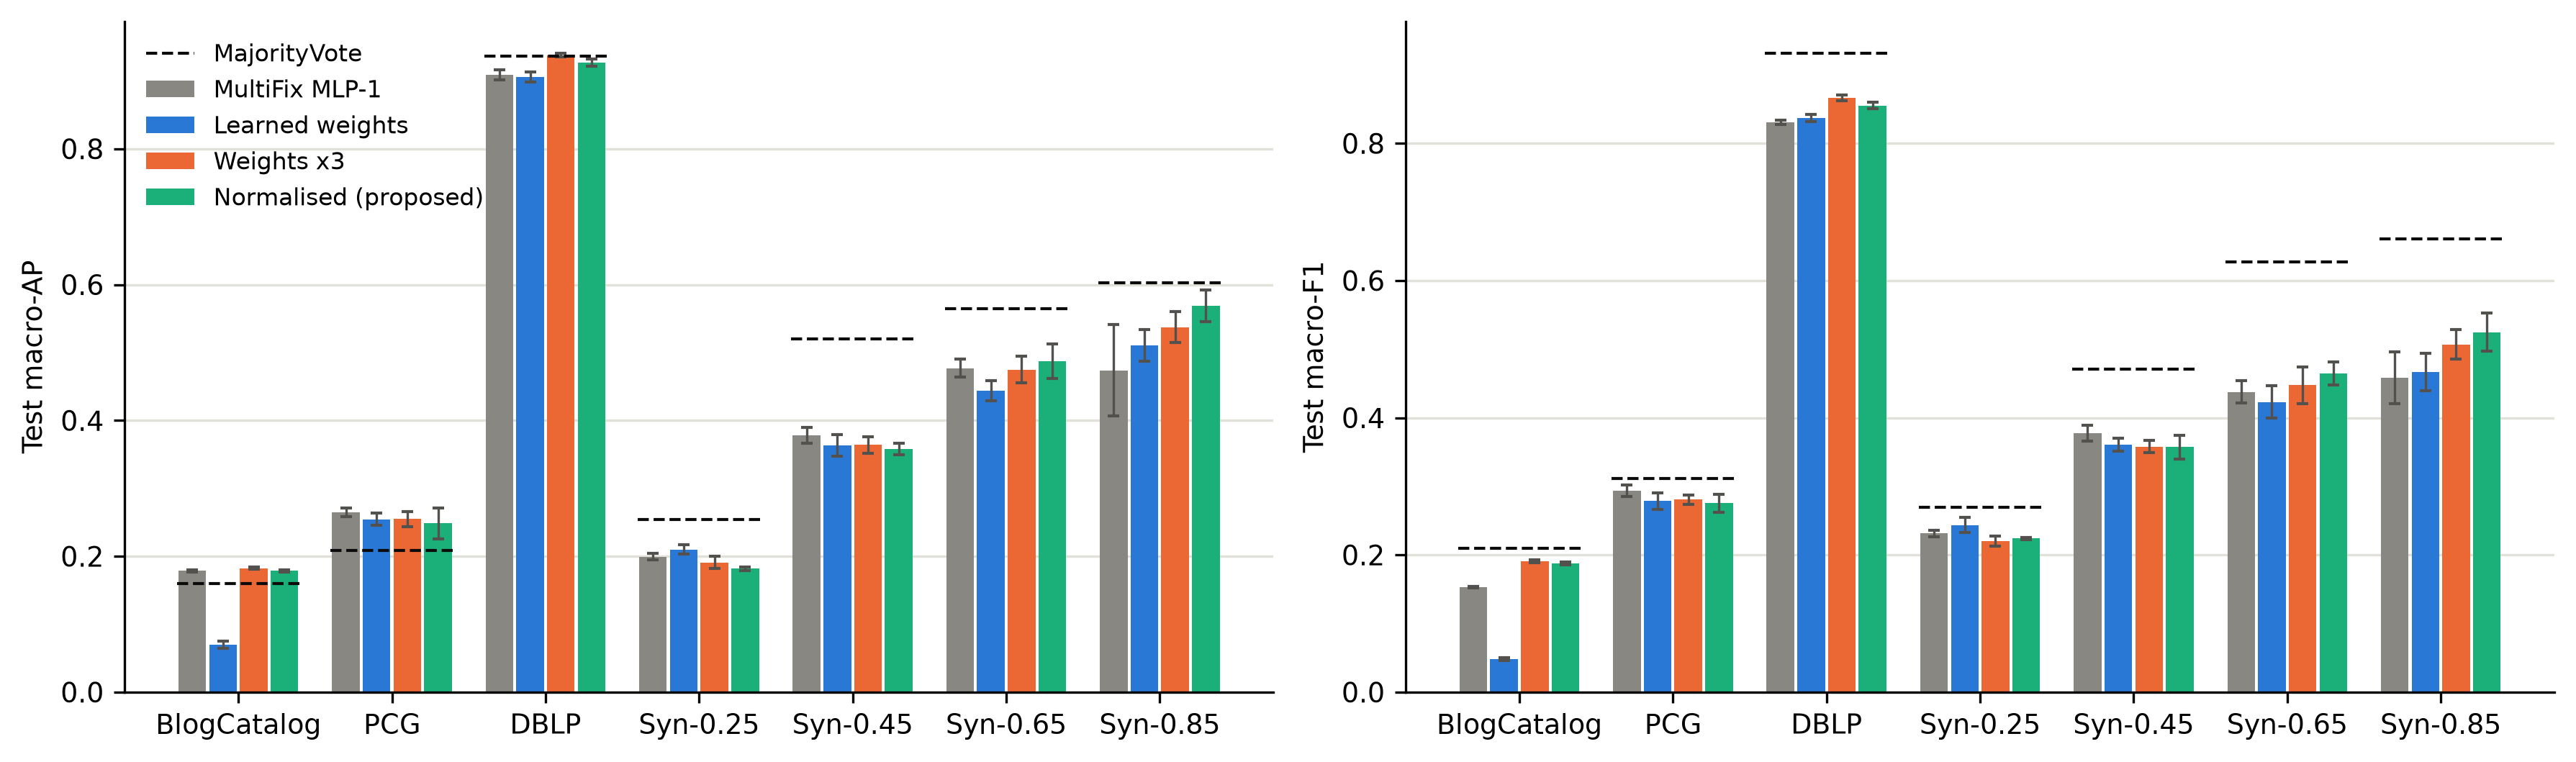

In [ ]:
# figure: test AP and macro-F1 of MultiFix and the three weighting variants, MajorityVote as reference
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), dpi=300, sharey=False)
hatches = ["", "//", "..", ""]
width = 0.2
x = np.arange(len(DATASETS))
for ax, metric in zip(axes, ["test_ap_macro", "test_macro_f1@per_label_threshold"]):
    mean, std = mean_std(metric, MAIN)
    for j, v in enumerate(MAIN):
        ax.bar(x + (j - 1.5) * width, mean.loc[v], width * 0.9, yerr=std.loc[v], label=v,
               color=VARIANT_COLORS[v], edgecolor="white", linewidth=0, capsize=2,
               error_kw=dict(elinewidth=0.8, ecolor="#52514e"))
    mv = [m for m, _ in BASELINES[metric]["MajorityVote"]]

    group_w = 4 * width  # 4 bars, each `width` wide (bar slots, not the 0.9 shrink)
    for i, m in enumerate(mv):
        ax.hlines(m, x[i] - group_w / 2, x[i] + group_w / 2,
                color="#0b0b0b", linewidth=1.0, linestyle="--", zorder=3,
                label="MajorityVote" if i == 0 else None)

    ax.set_xticks(x, [NAMES[d] for d in DATASETS])
    ax.set_ylabel("Test " + METRICS[metric])
    ax.grid(axis="x", visible=False)
axes[0].legend(ncol=1, fontsize=8, frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Testing H1.** H1 concerns the datasets on which a simple baseline (GCN, MajorityVote or CorGCN) beats GNN-MultiFix. On those datasets, weighting should improve **each** of AP, macro-F1 and AUROC by at least 10% relative to MultiFix. Below we list, for every dataset, which metrics a baseline wins on and the relative change of each weighting variant on each metric. Then we check whether the ≥10% criterion holds for all three metrics at once.

In [45]:
baseline_names = list(BASELINES["test_ap_macro"])
rel_rows, h1_rows = [], []
for d in DATASETS:
    beaten_on = [METRICS[m] for m in METRICS
                 if max(tables[m].loc[b, d] for b in baseline_names) > tables[m].loc["MultiFix MLP-1", d]]
    for v in MAIN[1:]:
        change = {METRICS[m]: 100 * (tables[m].loc[v, d] / tables[m].loc["MultiFix MLP-1", d] - 1) for m in METRICS}
        rel_rows.append({"dataset": NAMES[d], "variant": v, **{k: round(c, 1) for k, c in change.items()}})
        h1_rows.append({"dataset": NAMES[d], "variant": v,
                        "baseline beats MultiFix on": ", ".join(beaten_on) or "-",
                        "metrics with >= +10%": ", ".join(k for k, c in change.items() if c >= 10) or "-",
                        "H1 holds": bool(beaten_on) and all(c >= 10 for c in change.values())})

print("Relative change (%) of each weighting variant w.r.t. MultiFix MLP-1 (test, mean over splits):")
display(pd.DataFrame(rel_rows).pivot(index="variant", columns="dataset", values=list(METRICS.values()))
        .reindex(columns=[NAMES[d] for d in DATASETS], level=1))
h1 = pd.DataFrame(h1_rows)
display(h1[h1["variant"] == "Normalised (proposed)"].set_index("dataset").drop(columns="variant"))
print("Datasets where any weighting variant satisfies H1:", list(h1.loc[h1["H1 holds"], "dataset"].unique()) or "None")

Relative change (%) of each weighting variant w.r.t. MultiFix MLP-1 (test, mean over splits):


macro-AP                                                  macro-F1                                               macro-AUROC                                              
dataset               BlogCatalog  PCG DBLP Syn-0.25 Syn-0.45 Syn-0.65 Syn-0.85 BlogCatalog  PCG DBLP Syn-0.25 Syn-0.45 Syn-0.65 Syn-0.85 BlogCatalog  PCG DBLP Syn-0.25 Syn-0.45 Syn-0.65 Syn-0.85
variant                                                                                                                                                                                            
Learned weights             -61.0 -4.0 -0.4      5.3     -3.9     -6.9      7.8       -68.6 -5.2  0.8      5.4     -4.5     -3.4      1.8       -22.4 -1.0 -0.1      2.7     -2.4     -2.5     -2.1
Normalised (proposed)         0.0 -6.2  2.0     -8.8     -5.3      2.1     20.0        22.4 -6.1  3.0     -3.1     -5.5      6.2     14.5        -3.0 -1.8  0.7     -9.0     -5.7     -0.3      0.3
Weights x3                    2.1 -3.7  3.2     -4.2     -3.7     -0.4     13.4        24.5 -4.4  4.3     -4.7     -5.2      2.3     10.6        -1.6 -0.1  1.3     -3.0     -3.0     -1.6      0.7

,baseline beats MultiFix on,metrics with >= +10%,H1 holds
dataset,,,
BlogCatalog,macro-F1,macro-F1,False
PCG,macro-F1,-,False
DBLP,"macro-AP, macro-F1, macro-AUROC",-,False
Syn-0.25,"macro-AP, macro-F1, macro-AUROC",-,False
Syn-0.45,"macro-AP, macro-F1, macro-AUROC",-,False
Syn-0.65,"macro-AP, macro-F1",-,False
Syn-0.85,"macro-AP, macro-F1, macro-AUROC","macro-AP, macro-F1",False


Datasets where any weighting variant satisfies H1: None


**H1 is rejected.** A baseline beats MultiFix on every dataset (MajorityVote wins on most metrics; on BlogCatalog and PCG only on F1). However, no weighting variant improves all three metrics by at least 10% on any dataset. The proposed normalised variant gains ≥10% only on F1 for BlogCatalog and on AP and F1 for Syn-0.85, and AUROC never improves by more than about 1%. Weighting helps on the homophilic graphs (DBLP, Syn-0.65, Syn-0.85) and slightly hurts on the heterophilic ones (PCG, Syn-0.25, Syn-0.45), often within one standard deviation. The gain on Syn-0.85 is partly due to an unstable MultiFix baseline (std 0.067).

**How the weights are applied matters a lot.** The plain *Learned weights* variant collapses on BlogCatalog (AP 0.070 against 0.179). Scaling the weights by 3 or normalising the modules removes the collapse, so the cause is the smaller module scale, not the weighting itself.


### <font color=#4466ff>**5: Ablation: weighting or normalisation?**

<font color='white'>The normalised variant differs from MultiFix in two ways: it fuses the modules differently (projection, layer normalisation and sum), and it weights them per node. To separate the two, we keep the normalised fusion and replace the per-node weights by equal weights (1/3 each) or by one learned weight vector for the whole dataset. We also train single-module models to see where the signal lies.

In [46]:
ABLATION = ["Normalised (proposed)", "Equal weights (1/3)", "One learned weight vector per dataset",
            "Feature module only", "Label module only", "Positional module only"]
abl_mean, abl_std = mean_std("test_ap_macro", ABLATION)
abl = fmt3(abl_mean) + " ± " + fmt3(abl_std)
abl.columns = [NAMES[c] for c in abl.columns]
print("Test AP (mean ± std over 3 splits)")
display(abl)

gain = abl_mean.loc["Equal weights (1/3)"] - abl_mean.loc["Normalised (proposed)"]
print("Equal weights minus per-node weights (test AP):",
      ", ".join(f"{NAMES[d]} {g:+.3f}" for d, g in gain.items()))
mf = tables["test_ap_macro"].loc["MultiFix MLP-1"]
beats = [NAMES[d] for d in DATASETS if abl_mean.loc["Equal weights (1/3)", d] > mf[d]]
print(f"Normalised fusion with equal weights beats MultiFix MLP-1 on {len(beats)}/7 datasets: {beats}")
single = abl_mean.loc[ABLATION[3:]]
print("Best single module:", ", ".join(f"{NAMES[d]}: {single[d].idxmax().split()[0]}" for d in DATASETS))

Test AP (mean ± std over 3 splits)


,BlogCatalog,PCG,DBLP,Syn-0.25,Syn-0.45,Syn-0.65,Syn-0.85
variant,,,,,,,
Normalised (proposed),0.179 ± 0.002,0.248 ± 0.023,0.927 ± 0.005,0.182 ± 0.003,0.358 ± 0.009,0.487 ± 0.026,0.569 ± 0.024
Equal weights (1/3),0.187 ± 0.001,0.249 ± 0.024,0.924 ± 0.004,0.184 ± 0.006,0.382 ± 0.011,0.494 ± 0.021,0.602 ± 0.015
One learned weight vector per dataset,0.188 ± 0.002,0.250 ± 0.024,0.926 ± 0.002,0.188 ± 0.003,0.380 ± 0.012,0.502 ± 0.013,0.587 ± 0.036
Feature module only,0.043 ± 0.002,0.217 ± 0.007,0.909 ± 0.011,0.213 ± 0.009,0.360 ± 0.002,0.410 ± 0.008,0.436 ± 0.006
Label module only,0.043 ± 0.001,0.210 ± 0.004,0.919 ± 0.005,0.215 ± 0.008,0.329 ± 0.008,0.329 ± 0.014,0.366 ± 0.017
Positional module only,0.181 ± 0.002,0.230 ± 0.006,0.633 ± 0.007,0.187 ± 0.004,0.350 ± 0.011,0.450 ± 0.018,0.555 ± 0.005


Equal weights minus per-node weights (test AP): BlogCatalog +0.009, PCG +0.001, DBLP -0.003, Syn-0.25 +0.002, Syn-0.45 +0.024, Syn-0.65 +0.007, Syn-0.85 +0.033
Normalised fusion with equal weights beats MultiFix MLP-1 on 5/7 datasets: ['BlogCatalog', 'DBLP', 'Syn-0.45', 'Syn-0.65', 'Syn-0.85']
Best single module: BlogCatalog: Positional, PCG: Positional, DBLP: Label, Syn-0.25: Label, Syn-0.45: Feature, Syn-0.65: Positional, Syn-0.85: Positional


**The improvement over MultiFix comes from the normalised fusion, not from weighting the modules per node.** Equal weights and one weight vector per dataset do as well as the per-node gate on the real-world graphs, and as well or better on the synthetic ones (clearly on Syn-0.45 and Syn-0.85). With equal weights, the normalised model beats MultiFix on 5 of 7 datasets.

The single-module models show where the signal lies. On BlogCatalog the positional module alone matches the full model. On DBLP the label module alone almost does, while the positional module is weak. On PCG, Syn-0.65 and Syn-0.85 the positional module is the strongest single module. The label module alone barely improves with homophily (0.33 to 0.37 AP), although MajorityVote shows that neighbour labels become very informative (0.52 to 0.60). The label module of MultiFix therefore uses neighbour labels much less effectively than a simple vote does.

### <font color=#4466ff>**6: What do the weights learn? (H2, H3)**
</font>

We analyse the per-node weights $\alpha_i$ of the proposed normalised variant on the test nodes. 

For every node we compute:
* its **degree**;
* its **local label homophily**: the mean Jaccard overlap between its label set and those of its neighbours;
* its number of **labelled neighbours** (training nodes), i.e. how much label information can reach it.

In [47]:
def node_stats(G):
    """Degree, local label homophily and number of labelled neighbours of every node."""
    y = G.y.float()
    src, dst = G.edge_index
    n = G.num_nodes
    inter = (y[src] * y[dst]).sum(1)
    union = ((y[src] + y[dst]) > 0).float().sum(1).clamp(min=1)
    deg = torch.zeros(n).index_add_(0, src, torch.ones(src.shape[0]))
    local_h = torch.zeros(n).index_add_(0, src, inter / union) / deg.clamp(min=1)
    labelled = (G.train_mask & ~G.test_mask).float()
    n_labelled = torch.zeros(n).index_add_(0, src, labelled[dst])
    return deg, local_h, n_labelled


def pred_file(key, split, fusion="weighted-norm"):
    ds = key + ("-cleanval" if key == "dblp" else "")
    return f"{RESULTS_DIR}/preds/{ds}__relu__{fusion}__split_{split}__seed0.pt"


# one row per test node, dataset and split
frames = []
for key in DATASETS:
    for s in SPLITS:
        G = get_graph(key, s)
        deg, local_h, n_lab = node_stats(G)
        p = torch.load(pred_file(key, s))
        test = p["test_mask"]
        w = p["module_weights"][test]
        frames.append(pd.DataFrame({"ds": key, "split": s, "degree": deg[test].numpy(),
                                    "local_homophily": local_h[test].numpy(), "labelled_neighbours": n_lab[test].numpy(),
                                    "w_feature": w[:, 0].numpy(), "w_label": w[:, 1].numpy(),
                                    "w_positional": w[:, 2].numpy()}))
        del G
nodes = pd.concat(frames, ignore_index=True)
print(f"{len(nodes):,} test nodes over 7 datasets x 3 splits")

32,553 test nodes over 7 datasets x 3 splits


In [57]:
# mean weights per dataset (mean over splits of the mean over test nodes) and their spread across nodes
per_split = nodes.groupby(["ds", "split"]).agg(
    w_feature=("w_feature", "mean"), w_label=("w_label", "mean"), w_positional=("w_positional", "mean"),
    std_w_label_across_nodes=("w_label", "std"), degree=("degree", "mean"),
    labelled_neighbours=("labelled_neighbours", "mean"))
weights_table = per_split.groupby("ds").mean().reindex(list(DATASETS)).rename(index=NAMES)
weights_table.round(3)
weights_table.style.format("{:.2f}")

,w_feature,w_label,w_positional,std_w_label_across_nodes,degree,labelled_neighbours
ds,,,,,,
BlogCatalog,0.05,0.10,0.85,0.01,61.77,37.56
PCG,0.08,0.30,0.62,0.03,23.69,14.17
DBLP,0.47,0.43,0.10,0.09,4.79,2.79
Syn-0.25,0.15,0.37,0.48,0.01,107.32,64.42
Syn-0.45,0.05,0.34,0.61,0.07,16.98,10.16
Syn-0.65,0.27,0.31,0.42,0.05,7.69,4.57
Syn-0.85,0.26,0.24,0.50,0.05,4.56,2.72


**The weights are mainly a per-dataset choice.** Within one graph the standard deviation of $\alpha^L$ across nodes is at most about 0.09, much smaller than the differences between datasets. The positional module dominates on BlogCatalog and PCG, in line with the strength of DeepWalk on these benchmarks. The feature module gets the most weight on DBLP, the only graph with informative features.

#### <font color=#9944ff>**H2: does the mean label weight increase with graph homophily?**

Spearman correlation of graph homophily with the mean label weight over the 4 graphs x 3 splits: rho = -0.97 (p = 0.000)


w_feature        w_label        w_positional        labelled_neighbours       
               mean    std    mean    std         mean    std                mean    std
homophily                                                                               
0.25          0.148  0.024   0.370  0.024        0.482  0.048           64.421997  0.155
0.45          0.050  0.002   0.342  0.006        0.607  0.008           10.161000  0.093
0.65          0.271  0.018   0.308  0.024        0.421  0.038            4.569000  0.115
0.85          0.258  0.011   0.238  0.021        0.505  0.032            2.718000  0.116

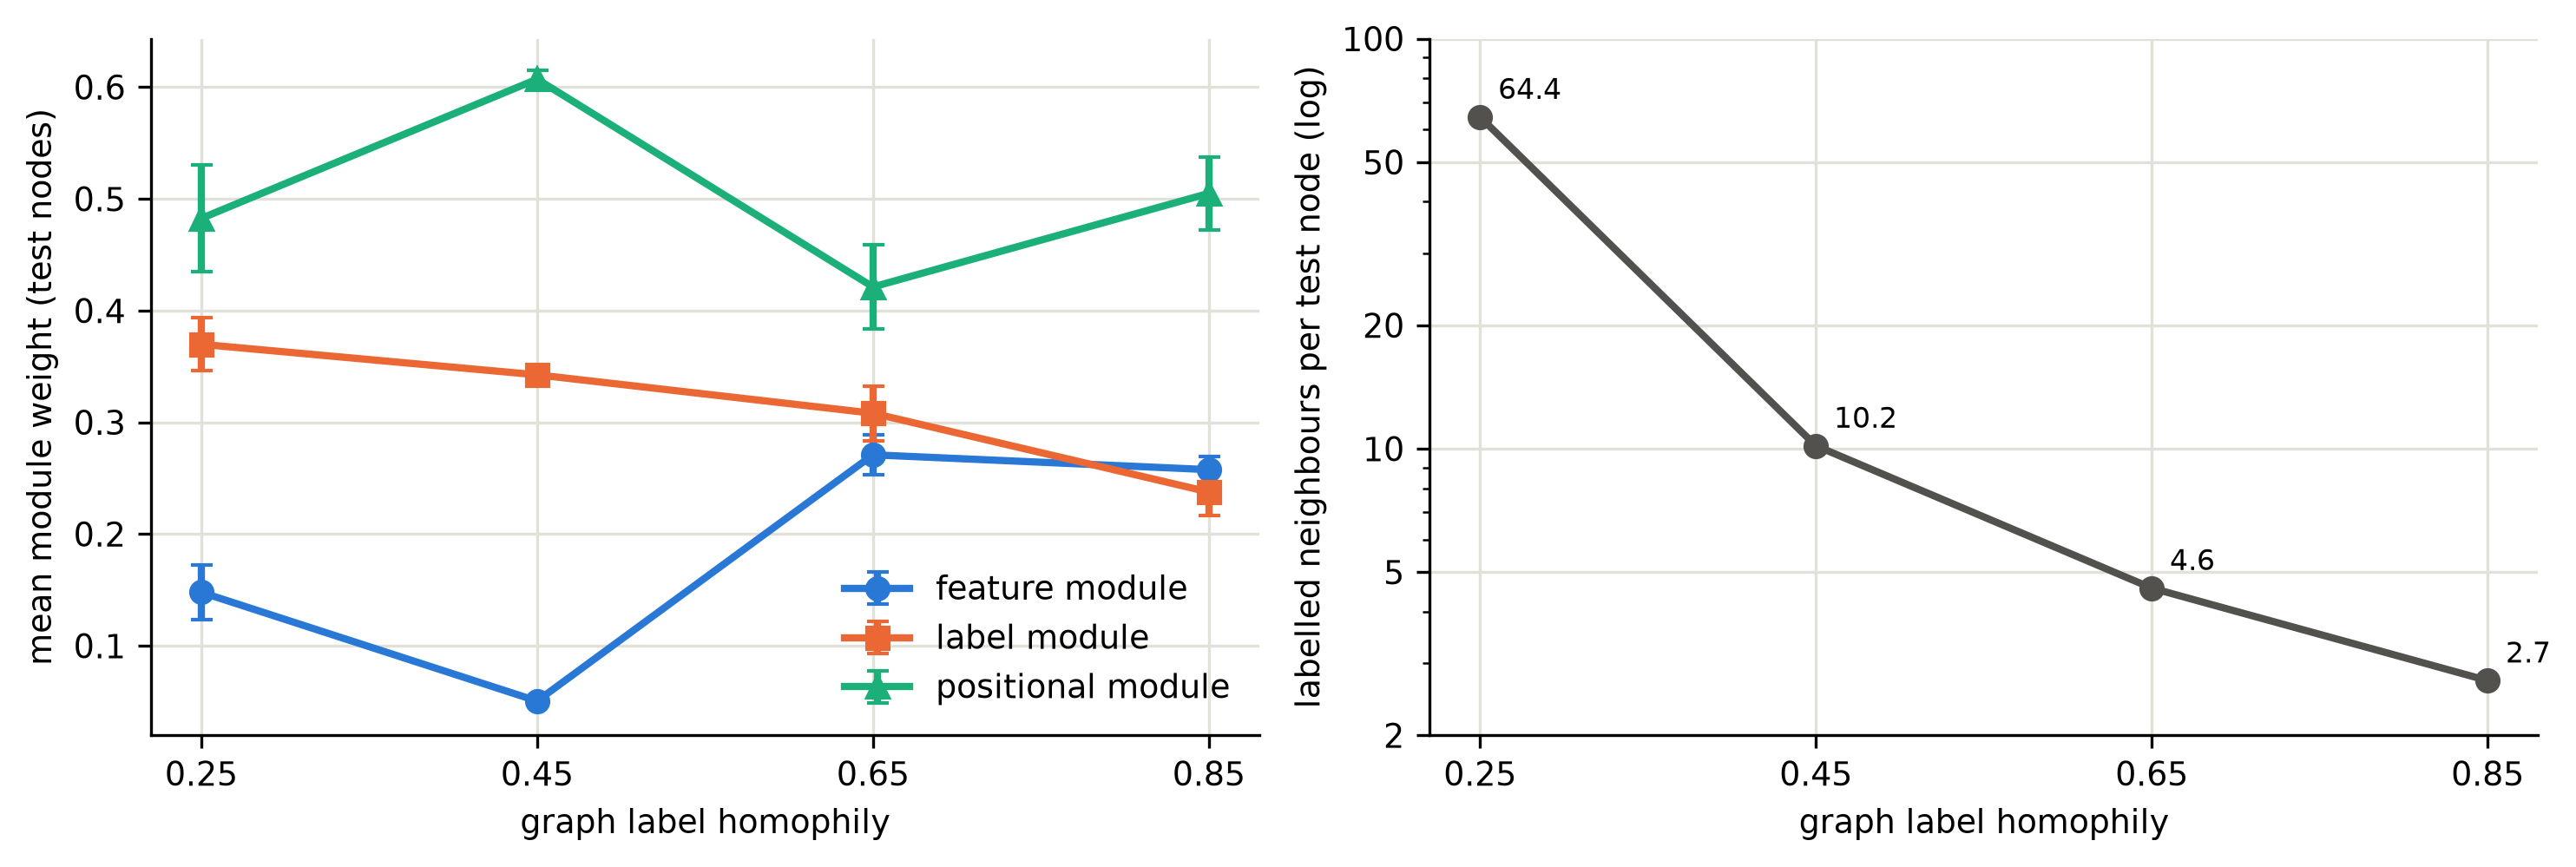

In [58]:
syn = per_split.loc[SYNTHETIC].reset_index()
syn["homophily"] = syn["ds"].map(SYN_HOMOPHILY)
rho, pval = spearmanr(syn["homophily"], syn["w_label"])
print(f"Spearman correlation of graph homophily with the mean label weight over the 4 graphs x 3 splits: "
      f"rho = {rho:+.2f} (p = {pval:.3f})")
display(syn.groupby("homophily")[["w_feature", "w_label", "w_positional", "labelled_neighbours"]].agg(["mean", "std"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), dpi=300)
markers = {"feature": "o", "label": "s", "positional": "^"}
for m in MODULES:
    g = syn.groupby("homophily")[f"w_{m}"]
    axes[0].errorbar(g.mean().index, g.mean(), yerr=g.std(), marker=markers[m], markersize=6, lw=2, capsize=3,
                     color=MODULE_COLORS[m], label=f"{m} module")
axes[0].set_xlabel("graph label homophily")
axes[0].set_ylabel("mean module weight (test nodes)")
axes[0].set_xticks(list(SYN_HOMOPHILY.values()))
axes[0].legend(frameon=False)
g = syn.groupby("homophily")["labelled_neighbours"]
axes[1].plot(g.mean().index, g.mean(), marker="o", markersize=6, lw=2, color="#52514e")
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
axes[1].yaxis.set_minor_formatter(plt.NullFormatter())
axes[1].set_yticks([2, 5, 10, 20, 50, 100])
axes[1].set_xlabel("graph label homophily")
axes[1].set_ylabel("labelled neighbours per test node (log)")
axes[1].set_xticks(list(SYN_HOMOPHILY.values()))
for xv, yv in zip(g.mean().index, g.mean()):
    axes[1].annotate(f"{yv:.1f}", (xv, yv), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.tight_layout()
plt.show()

**H2 is rejected.** On the synthetic graphs the mean label weight *decreases* with homophily, from about 0.37 at 0.25 to 0.24 at 0.85, while the feature weight rises. A likely reason is the confound noted in Section 1: the more homophilic graphs have far fewer edges, so a test node has on average 64 labelled neighbours on Syn-0.25 but fewer than 3 on Syn-0.85. Whether labels help therefore depends not only on homophily but also on how many neighbour labels reach a node.

#### <font color=#9944ff>**H3: within a graph, does a node's label weight correlate with its local homophily?**

In [50]:
def partial_spearman(a, b, c):
    """Spearman correlation of a and b after removing the (rank-)linear effect of c from both."""
    ra, rb, rc = (pd.Series(v).rank().to_numpy() for v in (a, b, c))
    res = lambda r: r - np.polyval(np.polyfit(rc, r, 1), rc)
    return np.corrcoef(res(ra), res(rb))[0, 1]


rows = []
for (key, s), g in nodes.groupby(["ds", "split"]):
    g = g[g["degree"] > 0]
    rows.append({"ds": key, "split": s,
                 "rho(local homophily, w_label)": spearmanr(g["local_homophily"], g["w_label"]).correlation,
                 "rho(degree, w_label)": spearmanr(g["degree"], g["w_label"]).correlation,
                 "rho(local homophily, degree)": spearmanr(g["local_homophily"], g["degree"]).correlation,
                 "partial rho(local homophily, w_label | degree)":
                     partial_spearman(g["local_homophily"], g["w_label"], g["degree"]),
                 "p < 0.05 (local homophily)": spearmanr(g["local_homophily"], g["w_label"]).pvalue < 0.05})
h3 = pd.DataFrame(rows)
h3_table = h3.groupby("ds").agg({c: "mean" for c in h3.columns[2:-1]} | {"p < 0.05 (local homophily)": "sum"})
h3_table = h3_table.reindex(list(DATASETS)).rename(index=NAMES)
h3_table = h3_table.rename(columns={"p < 0.05 (local homophily)": "splits with p < 0.05 (of 3)"})
print("Spearman correlations on the test nodes with degree > 0, mean over the 3 splits")
h3_table.round(2)

Spearman correlations on the test nodes with degree > 0, mean over the 3 splits


,"rho(local homophily, w_label)","rho(degree, w_label)","rho(local homophily, degree)","partial rho(local homophily, w_label | degree)",splits with p < 0.05 (of 3)
ds,,,,,
BlogCatalog,-0.27,0.04,-0.03,-0.27,3
PCG,-0.11,0.12,0.09,-0.12,2
DBLP,-0.18,0.09,-0.28,-0.16,3
Syn-0.25,0.01,0.18,-0.01,0.01,0
Syn-0.45,0.33,0.74,0.28,0.20,3
Syn-0.65,0.40,0.33,0.33,0.32,3
Syn-0.85,0.03,0.07,0.17,0.02,0


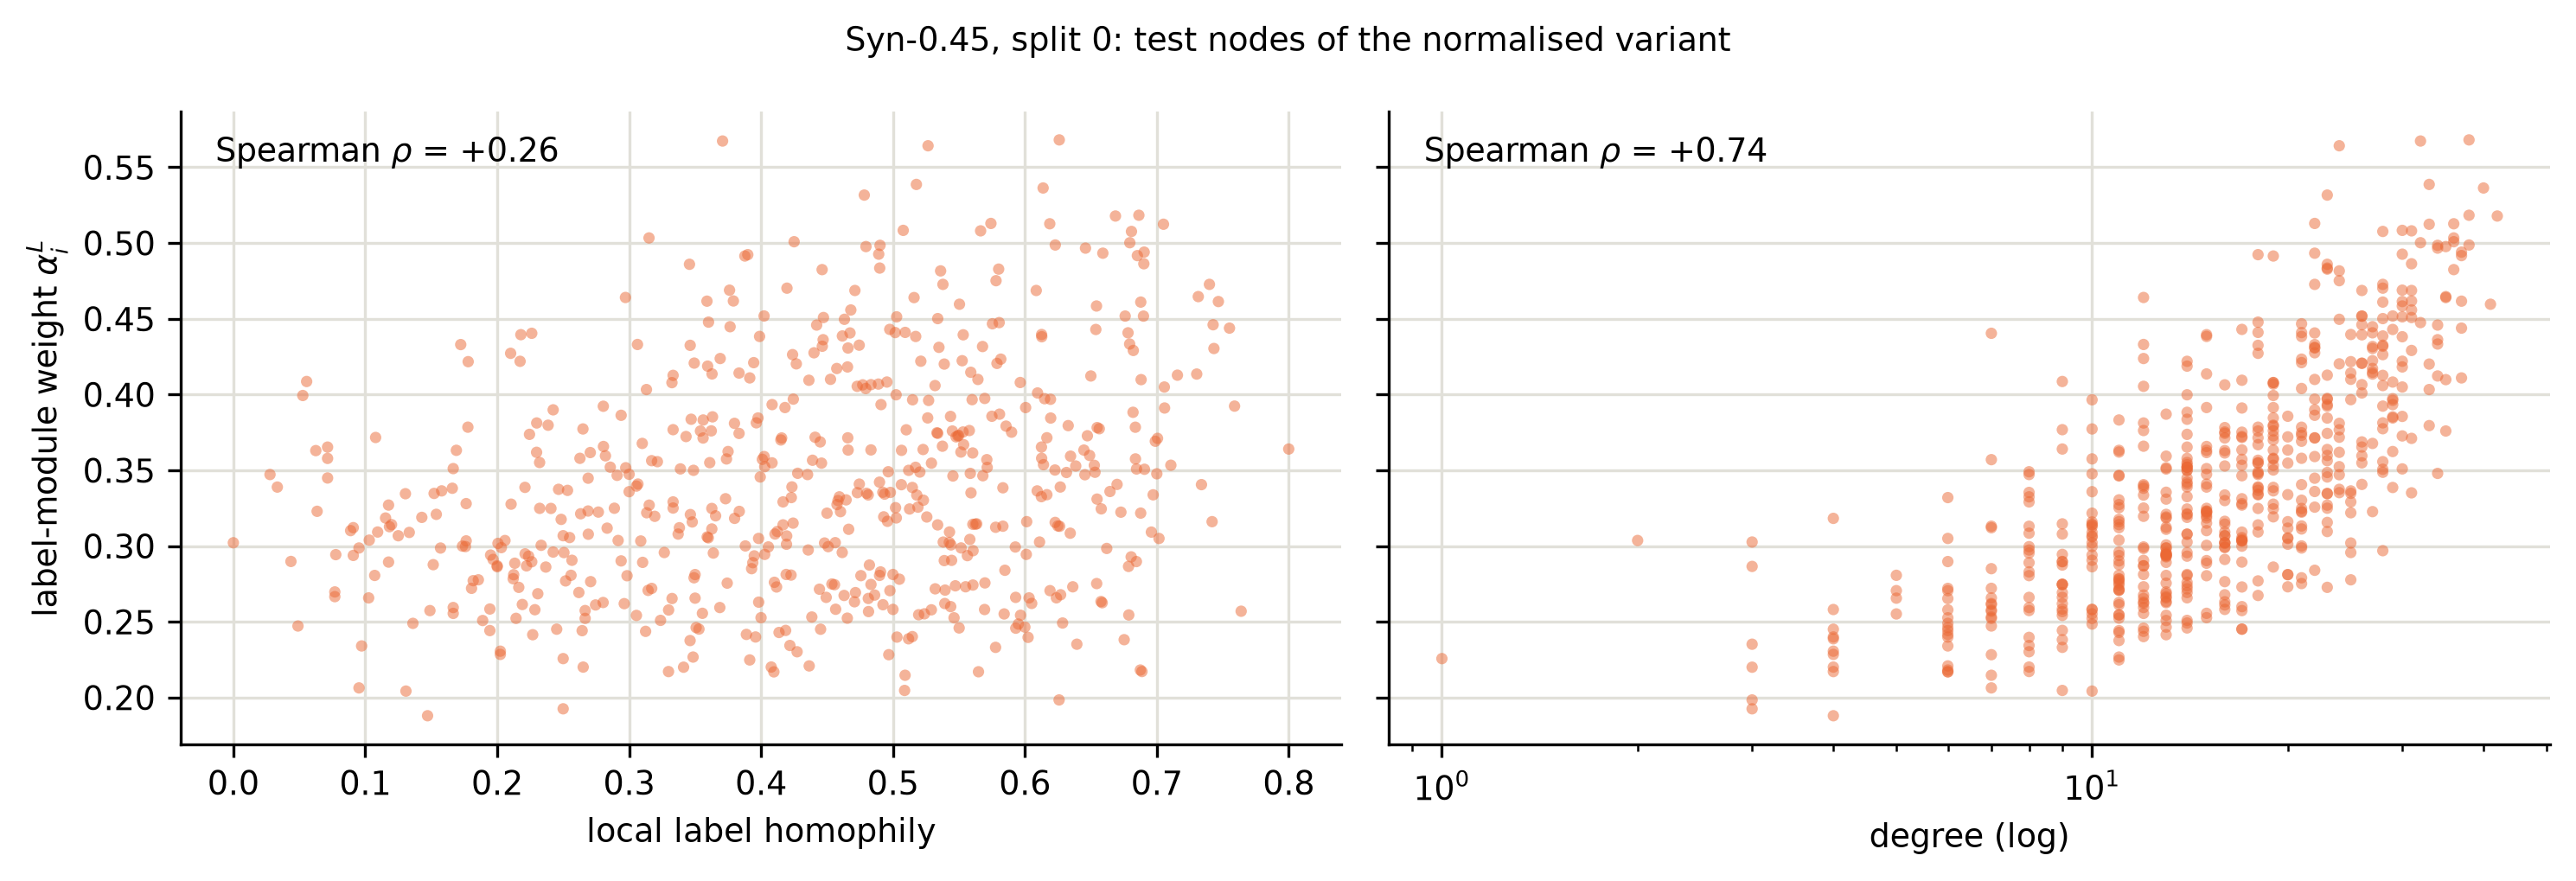

In [59]:
# per-node view on Syn-0.45 (split 0), where the correlations are strongest
g = nodes[(nodes["ds"] == "hyper_homo045") & (nodes["split"] == 0) & (nodes["degree"] > 0)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), dpi=300, sharey=True)
axes[0].scatter(g["local_homophily"], g["w_label"], s=10, alpha=0.5, color=MODULE_COLORS["label"], edgecolors="none")
axes[0].set_xlabel("local label homophily")
axes[0].set_ylabel(r"label-module weight $\alpha^L_i$")
axes[1].scatter(g["degree"], g["w_label"], s=10, alpha=0.5, color=MODULE_COLORS["label"], edgecolors="none")
axes[1].set_xscale("log")
axes[1].set_xlabel("degree (log)")
for ax, col in zip(axes, ["local_homophily", "degree"]):
    r = spearmanr(g[col], g["w_label"]).correlation
    ax.text(0.03, 0.92, rf"Spearman $\rho$ = {r:+.2f}", transform=ax.transAxes)
fig.suptitle("Syn-0.45, split 0: test nodes of the normalised variant", fontsize=9)
plt.tight_layout()
plt.show()

**H3 is only partially supported.** On Syn-0.45 and Syn-0.65, nodes with higher local homophily get a higher label weight ($\rho\approx0.33$ and $0.40$). On the other graphs the correlation is absent or negative. Even where it is positive, the label weight correlates more strongly with **degree** ($\rho\approx0.74$ on Syn-0.45). Degree and local homophily are themselves correlated there ($\rho\approx0.3$). Once degree is controlled for, the correlation with local homophily drops to about 0.20 on Syn-0.45 but stays at about 0.32 on Syn-0.65 (partial correlation column), so part of the effect is real and part runs through degree.

A plausible mechanism follows from how the label module is built. Unlabelled nodes enter it as the uniform vector $\frac1C\mathbf 1$. A node with few labelled neighbours therefore receives a nearly uniform, uninformative label representation, and a node with many labelled neighbours a sharper one. The gate can detect this from the module output itself, which would explain why it tracks degree. Together with H2, this suggests that the gate responds to *how much* label information reaches a node rather than to *whether* that information agrees with the node's labels.

### <font color=#4466ff>**7: Interpretability: are the weights faithful?**

</font>
The weights are a built-in explanation: they say how much each source of information was used for a node. Attention-like weights are not automatically faithful, however. We check this in three steps:
1. Do the three weighting variants agree on the weights?
2. Is the module with the highest weight also the best single module (Section 5)?
3. Fidelity: does removing the highest-weighted module at test time hurt the most?

In [52]:
# 1. mean label weight on the test nodes under the three variants
lw = runs[runs["variant"].isin(MAIN[1:])].groupby(["variant", "ds"])["test_weight_label"].mean().unstack()
lw = lw.reindex(index=MAIN[1:], columns=list(DATASETS)).rename(columns=NAMES)
print("1. Mean label-module weight on test nodes per variant")
display(lw.round(3))

# 2 + 3. highest weight vs best single module vs largest AP drop when removed (normalised variant)
ours = runs[runs["variant"] == "Normalised (proposed)"].copy()
for m in MODULES:
    ours[f"AP drop without {m}"] = ours["test_ap_macro"] - ours[f"test_ap_without_{m}"]
fid = ours.groupby("ds")[[f"test_weight_{m}" for m in MODULES] + [f"AP drop without {m}" for m in MODULES]].mean()
fid = fid.reindex(list(DATASETS))
fid["highest weight"] = fid[[f"test_weight_{m}" for m in MODULES]].idxmax(axis=1).str.replace("test_weight_", "")
fid["largest AP drop"] = fid[[f"AP drop without {m}" for m in MODULES]].idxmax(axis=1).str.replace("AP drop without ", "")
fid["best single module"] = [single[d].idxmax().split()[0].lower() for d in fid.index]
fid = fid.rename(index=NAMES)
print("2./3. Normalised variant on test nodes (mean over 3 splits)")
display(fid.round(3))
print(f"highest weight = largest AP drop on {(fid['highest weight'] == fid['largest AP drop']).sum()}/7 datasets; "
      f"highest weight = best single module on {(fid['highest weight'] == fid['best single module']).sum()}/7 datasets")

1. Mean label-module weight on test nodes per variant


ds,BlogCatalog,PCG,DBLP,Syn-0.25,Syn-0.45,Syn-0.65,Syn-0.85
variant,,,,,,,
Learned weights,0.032,0.027,0.002,0.474,0.075,0.071,0.092
Weights x3,0.141,0.261,0.083,0.224,0.103,0.078,0.085
Normalised (proposed),0.102,0.305,0.430,0.370,0.342,0.308,0.238


2./3. Normalised variant on test nodes (mean over 3 splits)


,test_weight_feature,test_weight_label,test_weight_positional,AP drop without feature,AP drop without label,AP drop without positional,highest weight,largest AP drop,best single module
ds,,,,,,,,,
BlogCatalog,0.050,0.102,0.848,-0.000,-0.001,0.138,positional,positional,positional
PCG,0.079,0.305,0.616,0.002,0.029,0.057,positional,positional,positional
DBLP,0.467,0.430,0.103,0.342,0.098,0.005,feature,feature,label
Syn-0.25,0.148,0.370,0.482,0.001,0.001,-0.027,positional,label,label
Syn-0.45,0.050,0.342,0.607,0.001,0.030,0.130,positional,positional,feature
Syn-0.65,0.271,0.308,0.421,0.061,0.023,0.115,positional,positional,positional
Syn-0.85,0.258,0.238,0.505,0.052,0.011,0.209,positional,positional,positional


highest weight = largest AP drop on 6/7 datasets; highest weight = best single module on 4/7 datasets


1. **The variants disagree.** On DBLP the label module gets very different weights under the three variants (about 0.002, 0.08 and 0.43) while all reach a similar AP. In the concatenation variants the classifier makes up for small weights, so only the normalised weights mean anything.
2. **Partly sensible.** The highest-weighted module is also the best single module on BlogCatalog, PCG, Syn-0.65 and Syn-0.85. On DBLP the feature and label modules are close both in weight and as single models.
3. **Mostly faithful, but the labels are overweighted.** Removing the highest-weighted module hurts the most on 6 of 7 graphs; on Syn-0.25 no single module matters. The label module, however, gets 0.24–0.43 of the weight, but removing it costs at most 0.03 AP outside DBLP. The weights point to the right main module but overstate the role of the labels.

### <font color=#4466ff>**8: Scalability**
</font>

The gate adds only a few small linear layers that are applied to each node separately, so its cost grows linearly with the number of nodes and does not depend on the number of edges. Below we compare the measured cost per run with MultiFix MLP-1. The memory column is the peak resident memory of the whole training process.

In [53]:
cost = runs[runs["variant"].isin(MAIN)].groupby(["ds", "variant"]).agg(
    params=("num_params", "first"), sec_per_epoch=("sec_per_epoch", "mean"), peak_rss=("peak_rss", "mean"))
ref = cost.xs("MultiFix MLP-1", level="variant")
rows = []
for (d, v), r in cost.iterrows():
    if v == "MultiFix MLP-1":
        continue
    rows.append({"dataset": NAMES[d], "variant": v, "extra parameters": int(r["params"] - ref.loc[d, "params"]),
                 "time per epoch (%)": round(100 * (r["sec_per_epoch"] / ref.loc[d, "sec_per_epoch"] - 1), 1),
                 "peak memory (%)": round(100 * (r["peak_rss"] / ref.loc[d, "peak_rss"] - 1), 1)})
cost_table = pd.DataFrame(rows).pivot(index="dataset", columns="variant").reindex([NAMES[d] for d in DATASETS])
print("Overhead relative to MultiFix MLP-1 (mean over 3 splits)")
cost_table

Overhead relative to MultiFix MLP-1 (mean over 3 splits)


extra parameters                                  time per epoch (%)                                  peak memory (%)                                 
variant      Learned weights Normalised (proposed) Weights x3    Learned weights Normalised (proposed) Weights x3 Learned weights Normalised (proposed) Weights x3
dataset                                                                                                                                                           
BlogCatalog            -6487                 82168      -6487                0.6                   5.3        0.3            -5.9                  -0.9       -4.5
PCG                      833                 86176        833                6.0                  17.1        5.4             1.4                   7.4        2.3
DBLP                    4188                 87628       4188               12.8                  34.2       10.3             0.3                  -0.8       -0.1
Syn-0.25                -692                 85436       -692                9.1                  -1.3       -5.1             4.5                 -10.3      -13.2
Syn-0.45                -692                 85436       -692                6.6                  19.7        6.1            -0.7                   7.2       -2.1
Syn-0.65                -692                 85436       -692               11.1                  34.8       10.5             7.2                  13.6        6.0
Syn-0.85                -692                 85436       -692               14.3                  41.3       15.9             2.8                  13.7        3.3

The normalised variant adds about 82–88K parameters (the projections $\mathbf F_m$ dominate), between −1% and +41% time per epoch, and changes peak memory by between −10% and +14%. These timings come from a laptop CPU with other processes running, so they are noisy; the time overhead is largest on the small graphs, where the fixed per-node cost of the gate weighs more. The real limits of all MultiFix variants lie elsewhere: DeepWalk embeddings are expensive to compute for large graphs and must be recomputed when the graph changes, and training is full-batch.

### <font color=#4466ff>**9: Training curves**
</font>

Training (dashed) and validation (solid) BCE on split 0, log–log. The dot marks the epoch with the lowest validation loss, which is evaluated.

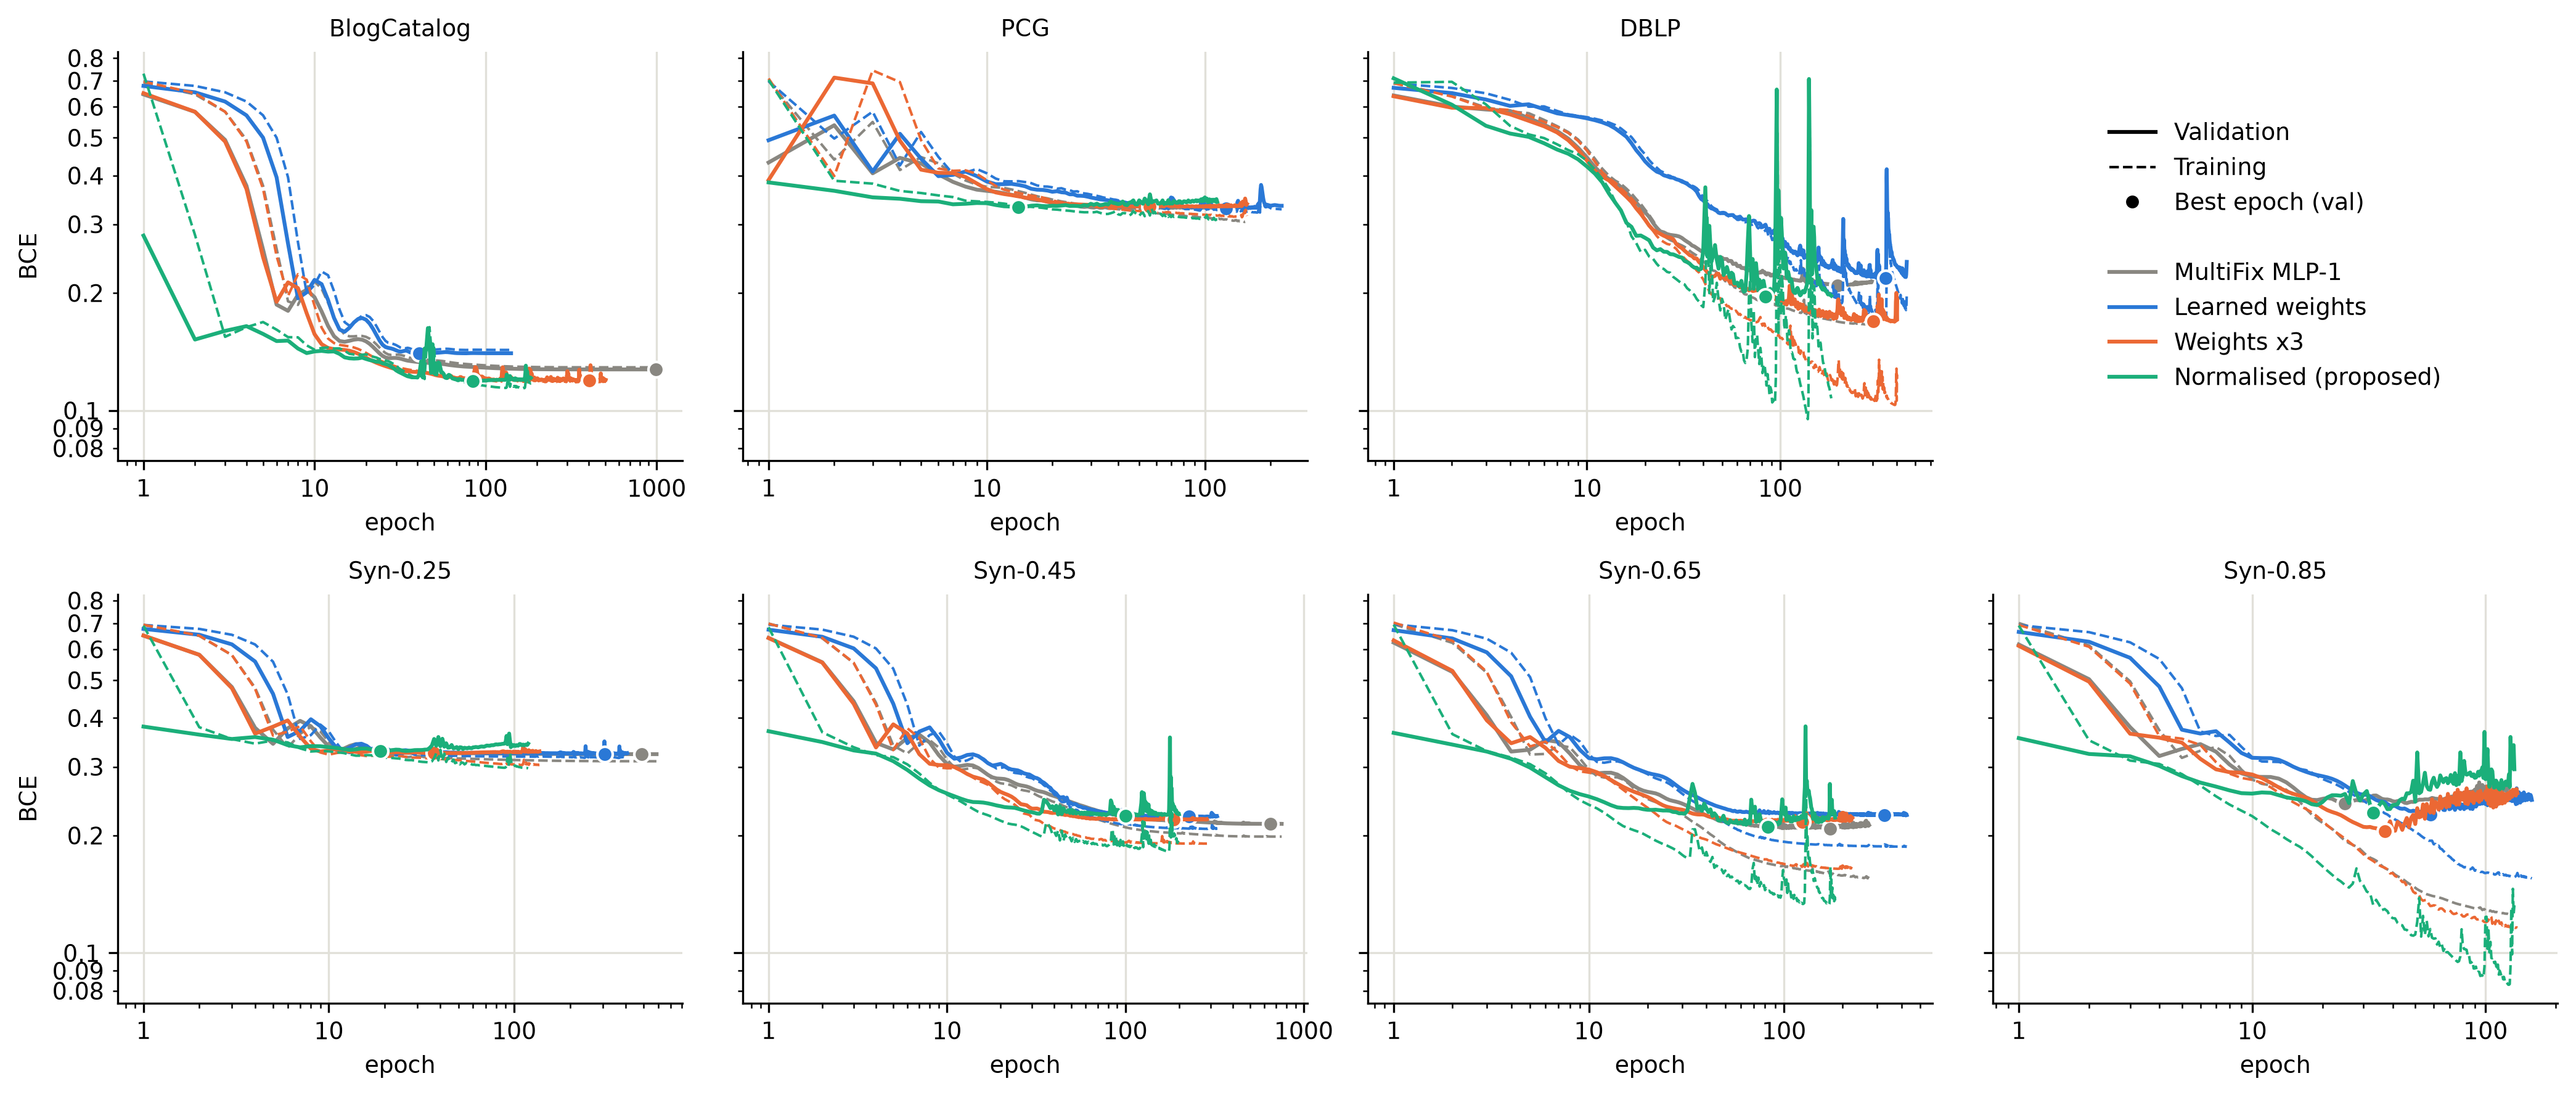

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), dpi=300, sharey=True)

# 3 plots on the top row, 4 on the bottom row; top-right cell is reserved for the legend
plot_axes = list(axes[0, :3]) + list(axes[1, :])
legend_ax = axes[0, 3]

for ax, key in zip(plot_axes, DATASETS):
    ds = key + ("-cleanval" if key == "dblp" else "")
    for v, fusion in zip(MAIN, ["concat", "weighted", "weighted-x3", "weighted-norm"]):
        c = pd.read_csv(f"{RESULTS_DIR}/curves/{ds}__relu__{fusion}__split_0__seed0.csv")
        e = c["epoch"] + 1
        ax.plot(e, c["val_loss"], color=VARIANT_COLORS[v], lw=1.5, label=v)
        ax.plot(e, c["train_loss"], color=VARIANT_COLORS[v], lw=1, ls="--")
        b = c["val_loss"].idxmin()
        ax.plot(e[b], c["val_loss"][b], "o", color=VARIANT_COLORS[v], markersize=6, markeredgecolor="white")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
    ax.yaxis.set_minor_formatter(plt.FormatStrFormatter("%g"))
    ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
    ax.set_title(NAMES[key], fontsize=9)
    ax.set_xlabel("epoch")

axes[0, 0].set_ylabel("BCE")
axes[1, 0].set_ylabel("BCE")

variant_handles, variant_labels = plot_axes[0].get_legend_handles_labels()
style_handles = [Line2D([], [], color="black", lw=1.5, ls="-"),
                 Line2D([], [], color="black", lw=1, ls="--"),
                 Line2D([], [], color="black", marker="o", ls="", markersize=6, markeredgecolor="white")]
style_labels = ["Validation", "Training", "Best epoch (val)"]

spacer = Line2D([], [], color="none")

legend_ax.axis("off")
legend_ax.legend(style_handles + [spacer] + variant_handles,
                 style_labels + [""] + variant_labels,
                 frameon=False, loc="center")

plt.tight_layout()
plt.show()

On BlogCatalog the plain *Learned weights* variant stops early (best epoch 40) at a clearly higher validation loss (0.140, against 0.119–0.127 for the others), and its validation loss jumps more from epoch to epoch than for the other variants. This matches its collapse in Section 4. On Syn-0.85 every variant reaches its lowest validation loss within 24–57 epochs while the training loss keeps falling, i.e. the models overfit early. This is one reason why the results there vary a lot between splits.

### <font color=#4466ff>**10: Conclusion**
</font>

*To what extent does node-specific weighting of the feature, label and positional representations improve GNN-MultiFix, and how do the learned weights relate to homophily?*

* **H1 (rejected).** Weighting does not consistently improve GNN-MultiFix. It raises AP by up to 20% on homophilic graphs and lowers it by up to 9% on heterophilic ones, and no variant improves AP, macro-F1 and AUROC all by ≥10% on any dataset.
* **Ablation.** Where the proposed variant helps, the gain comes from the normalised fusion: equal weights work as well as or better than node-specific ones. The gate learns mostly one combination of the modules per dataset.
* **H2 (rejected).** Across the synthetic graphs the mean label weight *decreases* with homophily. This is likely confounded by the far smaller number of labelled neighbours in the more homophilic graphs.
* **H3 (partially supported).** A node's label weight correlates with its local homophily only on Syn-0.45 and Syn-0.65 ($\rho\approx0.33$–$0.40$), and more strongly with its degree.
* **Interpretability.** Only the normalised weights can be read as importance. The highest-weighted module is the one whose removal hurts most on 6 of 7 graphs, but the weights overstate the role of the label module.

**Limitations.** One seed per split, and many differences are within one standard deviation. The gate size $d_g$ was not tuned. The baselines on DBLP use the original, overlapping validation set. The ablation does not separate projection, normalisation and summation. As in GNN-MultiFix, training nodes see their own label in the label module through the GCN self-loops.

**Future work.** The main open question is why the label module of GNN-MultiFix uses neighbour labels much less effectively than a simple majority vote, for example because five propagation layers mix labels from distant nodes. Only with a stronger label module can the gate show whether labels deserve more weight in homophilic regions. Weights per label instead of per node may also capture better which source of information helps for which label.